# IMPORT LIBRARY YANG DI BUTUHKAN

Library yang diimpor digunakan untuk membaca dan mengolah data, membuat visualisasi, membagi dataset, melatih serta mengevaluasi model, dan menyimpan model yang sudah dilatih.

## Tujuan Klasifikasi dan Batasan Penelitian

Penelitian ini mengklasifikasikan `base_severity` dari delapan fitur kategorikal CVSS. `cve_id` dipertahankan untuk pelacakan, tetapi tidak digunakan sebagai fitur; skor CVSS dan kolom lain yang berpotensi menjadi jalan pintas sudah dikeluarkan. Model memprediksi **severity CVSS**, bukan kemungkinan eksploitasi atau risiko aktual. Hasil berlaku untuk data yang lolos proses cleaning.

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score, classification_report
from sklearn.tree import DecisionTreeClassifier
import joblib


## 1. DATA LOADING

### 1.1. Memeriksa Jumlah Data dan Kolom
Dataset memiliki **374.917 baris** dan **17 kolom**.
### 1.2. Melihat 5 Baris Pertama
Menampilkan lima baris pertama untuk memahami struktur dan isi dataset.
### 1.3. Memeriksa Tipe Data
Memeriksa tipe data setiap kolom untuk mengetahui apakah data bertipe numerik, kategorikal, atau tanggal.
### 1.4. Memeriksa Deskripsi Dataset
Melihat ringkasan statistik deskriptif dari dataset.
### 1.5. Memeriksa Missing Values
Memeriksa jumlah nilai yang hilang pada setiap kolom. Memeriksa di tahun berapa nilai yang hiang tersebut berada dan apakah semua kolomnya berada di baris yang sama.
### 1.6. Memeriksa Data Duplikat
Memeriksa apakah terdapat baris data yang duplikat.
### 1.7. Memeriksa Distribusi `base_severity` (Kandidat Target)
Distribusi kelas menunjukkan ketidakseimbangan data.
Kelas **MEDIUM** dan **HIGH** memiliki jumlah sampel lebih banyak dibandingkan kelas lainnya.
### 1.8. Memeriksa Distribusi `cisa_kev` (Kandidat Target)
Seluruh baris pada kolom `cisa_kev` memiliki nilai **`False`**.
Kolom ini tidak memiliki variasi nilai sehingga tidak dapat digunakan sebagai target klasifikasi yang bermakna pada dataset ini.

Membaca dataset dari file CSV lalu melihat jumlah baris dan kolomnya. Pastikan file CSV berada di folder kerja notebook atau sesuaikan path jika diperlukan.

In [3]:
train = pd.read_csv("cve_cisa_epss_enriched_dataset.csv")
print("Ukuran Dataset: ", train.shape)

Ukuran Dataset:  (374917, 17)


Menampilkan lima baris pertama untuk melihat bentuk data, nama kolom, dan contoh isi setiap kolom.

In [4]:
# Memeriksa 5 baris pertama
train.head()

,cve_id,base_severity,base_score,exploitability_score,impact_score,epss_score,epss_perc,cisa_kev,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality_impact,integrity_impact,availability_impact,published_date
0,CVE-1999-0095,HIGH,10.0,10.0,10.0,0.16317,0.96889,False,NETWORK,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1988-10-01 04:00:00
1,CVE-1999-0082,HIGH,10.0,10.0,10.0,0.08281,0.94791,False,NETWORK,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1988-11-11 05:00:00
2,CVE-1999-1471,HIGH,7.2,3.9,10.0,0.00503,0.41171,False,LOCAL,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1989-01-01 05:00:00
3,CVE-1999-1122,MEDIUM,4.6,3.9,6.4,0.00383,0.30219,False,LOCAL,LOW,NaN,NaN,NaN,PARTIAL,PARTIAL,PARTIAL,1989-07-26 04:00:00
4,CVE-1999-1467,HIGH,10.0,10.0,10.0,0.10249,0.95581,False,NETWORK,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1989-10-26 04:00:00


Memeriksa tipe data dan jumlah nilai yang terisi pada setiap kolom.

In [5]:
# Memeriksa tipe data
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 374917 entries, 0 to 374916
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   cve_id                  374917 non-null  str    
 1   base_severity           374917 non-null  str    
 2   base_score              374917 non-null  float64
 3   exploitability_score    374917 non-null  float64
 4   impact_score            374917 non-null  float64
 5   epss_score              374646 non-null  float64
 6   epss_perc               374646 non-null  float64
 7   cisa_kev                374917 non-null  bool   
 8   attack_vector           374917 non-null  str    
 9   attack_complexity       374917 non-null  str    
 10  privileges_required     302512 non-null  str    
 11  user_interaction        302512 non-null  str    
 12  scope                   302512 non-null  str    
 13  confidentiality_impact  374917 non-null  str    
 14  integrity_impact        374917 

Menampilkan statistik ringkas dataset. `include='all'` juga mencakup kolom kategorikal.

In [6]:
train.describe(include="all")

,cve_id,base_severity,base_score,exploitability_score,impact_score,epss_score,epss_perc,cisa_kev,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality_impact,integrity_impact,availability_impact,published_date
count,374917,374917,374917.000000,374917.000000,374917.000000,374646.000000,374646.000000,374917,374917,374917,302512,302512,302512,374917,374917,374917,374917
unique,374917,5,NaN,NaN,NaN,NaN,NaN,1,4,3,3,2,2,5,5,5,346510
top,CVE-1999-0095,MEDIUM,NaN,NaN,NaN,NaN,NaN,False,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH,2004-12-31 05:00:00.000
freq,1,170990,NaN,NaN,NaN,NaN,NaN,374917,283041,315686,168647,208089,240979,153489,129956,149772,1098
mean,NaN,NaN,6.804152,3.728966,4.464240,0.027521,0.507326,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,1.798358,2.587553,1.926676,0.090306,0.287467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,0.000000,0.100000,0.000000,0.000490,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,5.400000,1.800000,2.900000,0.003450,0.259410,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,7.000000,2.800000,3.700000,0.006840,0.511440,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,7.800000,3.900000,5.900000,0.016350,0.756130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Menghitung jumlah nilai kosong pada setiap kolom.

In [7]:
# Memeriksa missing values
train.isnull().sum()

cve_id                        0
base_severity                 0
base_score                    0
exploitability_score          0
impact_score                  0
epss_score                  271
epss_perc                   271
cisa_kev                      0
attack_vector                 0
attack_complexity             0
privileges_required       72405
user_interaction          72405
scope                     72405
confidentiality_impact        0
integrity_impact              0
availability_impact           0
published_date                0
dtype: int64

Memeriksa jumlah baris yang seluruh nilainya identik pada dataset awal.

In [8]:
# Memeriksa duplikat
train.duplicated().sum()

np.int64(0)

Melihat jumlah data pada setiap kelas `base_severity` untuk memahami distribusi kandidat target.

In [9]:
# Distribusi tingkat keparahan
train["base_severity"].value_counts(dropna=False)


base_severity
MEDIUM      170990
HIGH        150664
CRITICAL     36970
LOW          16246
NONE            47
Name: count, dtype: int64

Memeriksa variasi nilai pada `cisa_kev` untuk melihat apakah kolom ini memiliki lebih dari satu nilai.

In [10]:
train["cisa_kev"].value_counts(dropna=False)

cisa_kev
False    374917
Name: count, dtype: int64

Mengubah jumlah missing values menjadi persentase agar kolom yang memiliki banyak nilai kosong lebih mudah dikenali.

In [11]:
# Menghitung presentase nilai kosong dalam kolom
missing_percent = (train.isnull().sum() / len(train)) * 100
missing_percent[missing_percent > 0].sort_values(ascending=False)

privileges_required    19.312274
scope                  19.312274
user_interaction       19.312274
epss_score              0.072283
epss_perc               0.072283
dtype: float64

Memeriksa apakah missing values pada tiga kolom ini muncul bersamaan dalam baris yang sama atau tersebar pada baris berbeda.

In [12]:
colms = ["user_interaction", "privileges_required", "scope"]

# HItung berapa baris yang kosong pada ketiga kolom
all_missing = train[colms].isnull().all(axis=1).sum()
# Hitng baris kosong pada setidaknya 1 kolom
any_missing = train[colms].isnull().any(axis=1).sum()

print("Kosong pada ke-3 kolom: ", all_missing)
print("Kosong pada minmal satu kolom: ", any_missing)

Kosong pada ke-3 kolom:  72405
Kosong pada minmal satu kolom:  72405


Mengelompokkan data berdasarkan tahun publikasi untuk melihat jumlah baris dan missing value pada `user_interaction` di setiap tahun.

In [13]:
year = pd.to_datetime(train["published_date"], errors="coerce").dt.year
missing_by_year = train.groupby(year).agg(
    jumlah_baris = ("cve_id", "size"),
    jumlah_missing = ("user_interaction", lambda s: s.isnull().sum())
)

missing_by_year["persen_missing"] = (
    missing_by_year["jumlah_missing"] / missing_by_year["jumlah_baris"] * 100
)

print(missing_by_year)
# Memeriksa apakah ada missing value yang lebih dari tahun 2002
missing_by_year[missing_by_year.index > 2002]

                jumlah_baris  jumlah_missing  persen_missing
published_date                                              
1988.0                     2               2      100.000000
1989.0                     3               3      100.000000
1990.0                    11              10       90.909091
1991.0                    15              15      100.000000
1992.0                    13              13      100.000000
1993.0                    13              13      100.000000
1994.0                    25              25      100.000000
1995.0                    25              24       96.000000
1996.0                    74              72       97.297297
1997.0                   252             242       96.031746
1998.0                   246             236       95.934959
1999.0                   894             885       98.993289
2000.0                  1019            1009       99.018646
2001.0                  1675            1637       97.731343
2002.0                  

,jumlah_baris,jumlah_missing,persen_missing
published_date,,,


Memeriksa apakah nilai kosong pada `epss_perc` dan `epss_score` muncul pada baris yang sama.

In [14]:
colms = ["epss_perc", "epss_score"]

# HItung berapa baris yang kosong pada kedua kolom
all_missing = train[colms].isnull().all(axis=1).sum()
# Hitng baris kosong pada setidaknya 1 kolom
any_missing = train[colms].isnull().any(axis=1).sum()

print("Kosong pada ke-2 kolom: ", all_missing)
print("Kosong pada minmal satu kolom: ", any_missing)

Kosong pada ke-2 kolom:  271
Kosong pada minmal satu kolom:  271


## 2. Data Cleaning
### 2.1 Mengapus Missing Values
baris yang nilainya hilang dihapus karena baris tersebut berada di tahun yang lampau tepatnya 1988-2002 yang di mana CVSS 3 belum digunakan.
### 2.2 Menghapus kolom yang tidak digunakan.


Baris yang memiliki nilai kosong pada salah satu kolom yang dipilih akan dihapus. Jumlah data sebelum dan sesudahnya ditampilkan untuk melihat dampak cleaning.

### Dampak Cleaning

Sebanyak **72.405 dari 374.917 baris (19,31%)** dihapus karena `user_interaction`, `privileges_required`, dan `scope` kosong bersamaan. Dataset tersisa **302.512 baris**.

NVD mulai melakukan penilaian dengan CVSS v3.0 pada Desember 2015 ([timeline NVD](https://www.nist.gov/itl/nvd/nvd-news)). Maka dari itu `missing_by_year` yang berada di bawah 2002 dihapuskan.

In [15]:
colms = ["user_interaction", "privileges_required", "scope"]
print("Jumlah data sebelum di bersihkan: ", len(train))
train_clean = train.dropna(subset=colms).copy()
print("Jumlah data sesudah di bersihkan: ", len(train_clean))
train_clean.isnull().sum()

Jumlah data sebelum di bersihkan:  374917
Jumlah data sesudah di bersihkan:  302512


cve_id                      0
base_severity               0
base_score                  0
exploitability_score        0
impact_score                0
epss_score                271
epss_perc                 271
cisa_kev                    0
attack_vector               0
attack_complexity           0
privileges_required         0
user_interaction            0
scope                       0
confidentiality_impact      0
integrity_impact            0
availability_impact         0
published_date              0
dtype: int64

Menghapus kolom yang sudah dipilih dari dataset, lalu melihat struktur data yang tersisa untuk analisis berikutnya.

In [16]:
kolom = ["base_score",
        "exploitability_score",
        "impact_score",
        "epss_score",
        "epss_perc",
        "cisa_kev",
        "published_date"
        ]
df = train_clean.drop(columns=kolom)
df.info()
df.head()


<class 'pandas.DataFrame'>
Index: 302512 entries, 6 to 374916
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   cve_id                  302512 non-null  str  
 1   base_severity           302512 non-null  str  
 2   attack_vector           302512 non-null  str  
 3   attack_complexity       302512 non-null  str  
 4   privileges_required     302512 non-null  str  
 5   user_interaction        302512 non-null  str  
 6   scope                   302512 non-null  str  
 7   confidentiality_impact  302512 non-null  str  
 8   integrity_impact        302512 non-null  str  
 9   availability_impact     302512 non-null  str  
dtypes: str(10)
memory usage: 25.4 MB


,cve_id,base_severity,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality_impact,integrity_impact,availability_impact
6,CVE-1999-0084,HIGH,LOCAL,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
90,CVE-1999-0066,CRITICAL,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
128,CVE-1999-0022,HIGH,LOCAL,LOW,LOW,NONE,UNCHANGED,HIGH,HIGH,HIGH
168,CVE-1999-0043,CRITICAL,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
194,CVE-1999-0236,HIGH,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,NONE,NONE


Memeriksa missing values dan duplikasi setelah kolom tertentu dihapus.

In [17]:
print(f"Missing Values:\n{df.isnull().sum()}")
print(f"baris duplikat: {df.duplicated().sum()}")
print(f"baris duplikat CVE_ID: {df["cve_id"].duplicated().sum()}")

Missing Values:
cve_id                    0
base_severity             0
attack_vector             0
attack_complexity         0
privileges_required       0
user_interaction          0
scope                     0
confidentiality_impact    0
integrity_impact          0
availability_impact       0
dtype: int64
baris duplikat: 0
baris duplikat CVE_ID: 0


Menghapus baris yang identik berdasarkan kolom yang masih tersisa, lalu memeriksa jumlah duplikat dan distribusi target setelah proses tersebut.

In [18]:
df = df.drop_duplicates()
print(f"baris duplikat: {df.duplicated().sum()}")
df["base_severity"].value_counts()
df.shape
df.info()

baris duplikat: 0
<class 'pandas.DataFrame'>
Index: 302512 entries, 6 to 374916
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   cve_id                  302512 non-null  str  
 1   base_severity           302512 non-null  str  
 2   attack_vector           302512 non-null  str  
 3   attack_complexity       302512 non-null  str  
 4   privileges_required     302512 non-null  str  
 5   user_interaction        302512 non-null  str  
 6   scope                   302512 non-null  str  
 7   confidentiality_impact  302512 non-null  str  
 8   integrity_impact        302512 non-null  str  
 9   availability_impact     302512 non-null  str  
dtypes: str(10)
memory usage: 25.4 MB


### Validasi Duplikat Setelah Cleaning

Pada tahap ini `cve_id` masih disertakan dan setiap ID unik, sehingga `df.duplicated()` menghasilkan **0** dan `drop_duplicates()` tidak membuang baris. Ketika `cve_id` disisihkan untuk EDA, saya menemukan **300.692 baris berulang (99,40%)** berdasarkan kombinasi kolom yang tersisa. Itu tidak otomatis berarti CVE-nya duplikat: CVE berbeda dapat memiliki kombinasi fitur dan severity yang sama.

## 3. EDA (1)
### 3.1 Melihat statistik distribusi


Histogram ini memperlihatkan distribusi tiap kolom di `df`. Untuk fitur kategorikal, diagram batang biasanya lebih mudah digunakan untuk membandingkan jumlah tiap kategori.

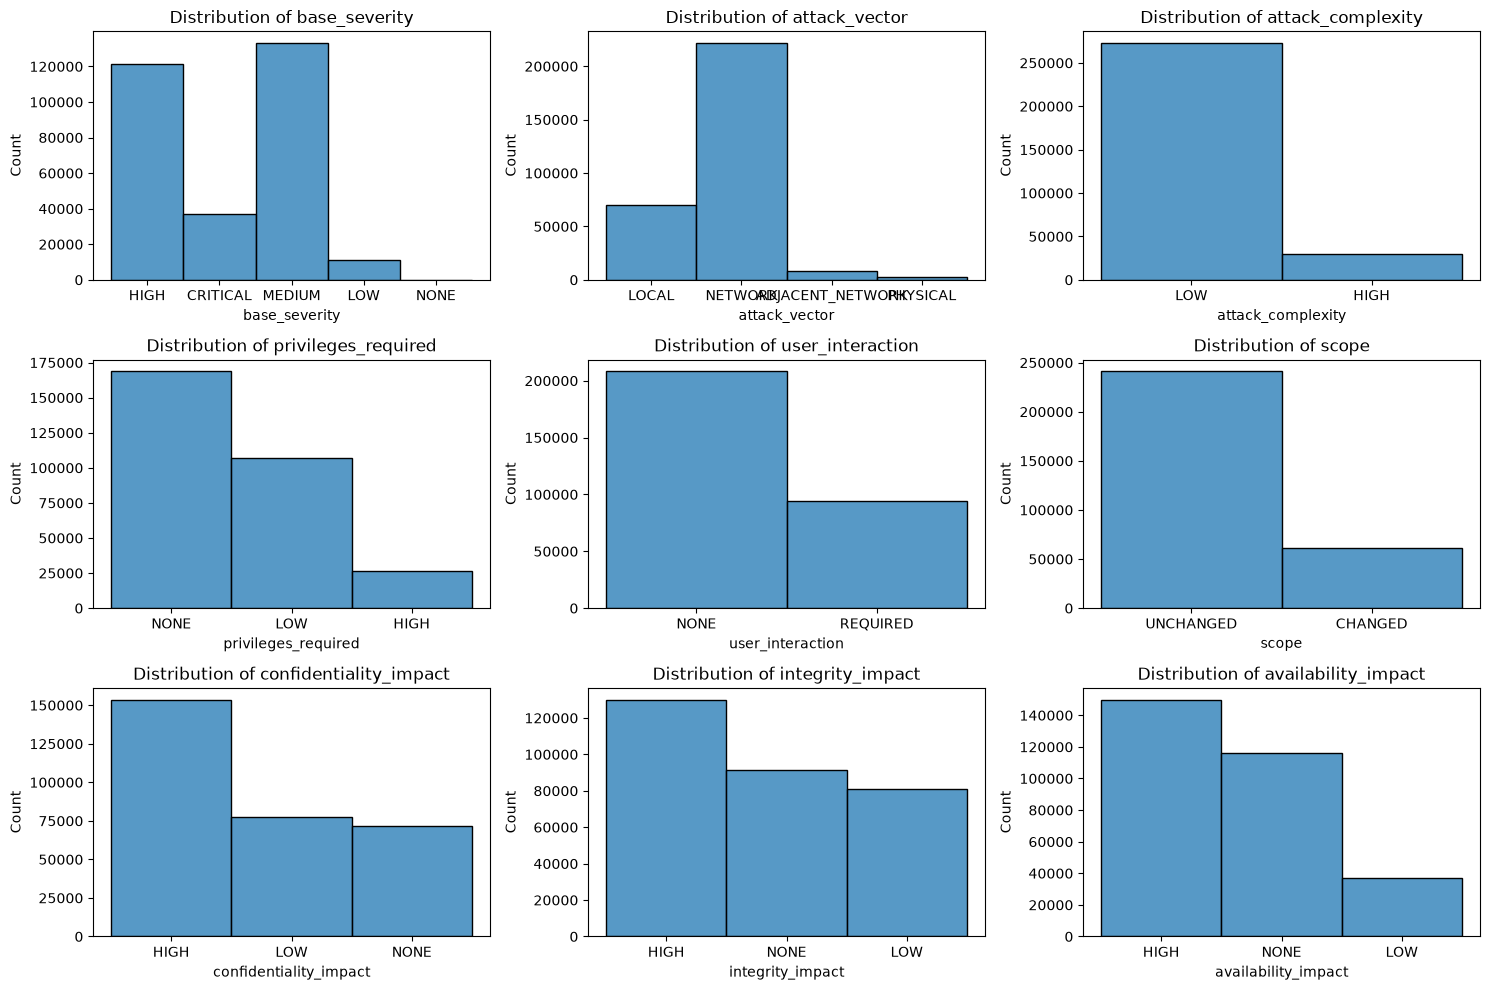

np.int64(300692)

In [19]:
# Hapus sementara cve_id dari df
df_plot = df.drop(columns=["cve_id"])

# Visualisasi distribusi data
plt.figure(figsize=(15, 10))

for i, column in enumerate(df_plot, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df_plot[column])
    plt.title(f"Distribution of {column}")

plt.tight_layout()
plt.show()
df_plot.duplicated().sum()

## 4. Melakukan split & Encododing
Split di lakukan dengan memisahkan target dan fitur terlebih dahulu, lalu di lakukan encoding menggunakan ONE-HOT-ENCODING. Data latih dan data uji dengan `stratify=y` agar proporsi kelas tetap terjaga.

In [20]:
# Memisahkan fitur (X) dan target (y)*
X = df.drop(columns=["base_severity", "cve_id"])
y = df["base_severity"]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
x_train = pd.get_dummies(x_train)
x_test = pd.get_dummies(x_test)

# Menyamakan kolom training dan testing
x_test = x_test.reindex(columns=x_train.columns, fill_value=0)

# menghitung jumlah data*
print("Jumlah data: ",len(X))
# Menghitung jumlah data pada x_train*
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test*
print("Jumlah data test: ",len(x_test))




Jumlah data:  302512
Jumlah data latih:  211758
Jumlah data test:  90754


### Catatan Split dan Preprocessing

Pembagian saat ini menghasilkan **211758 data latih** dan **90754 data uji** (70:30), lalu one-hot encoding dilakukan setelah split dan kolom uji disejajarkan dengan kolom latih.

### 5. EDA (2)
Melihat korelasi menggunakan heatmap dan melihat korelasi fitur dengan target berdasarkan kategori.

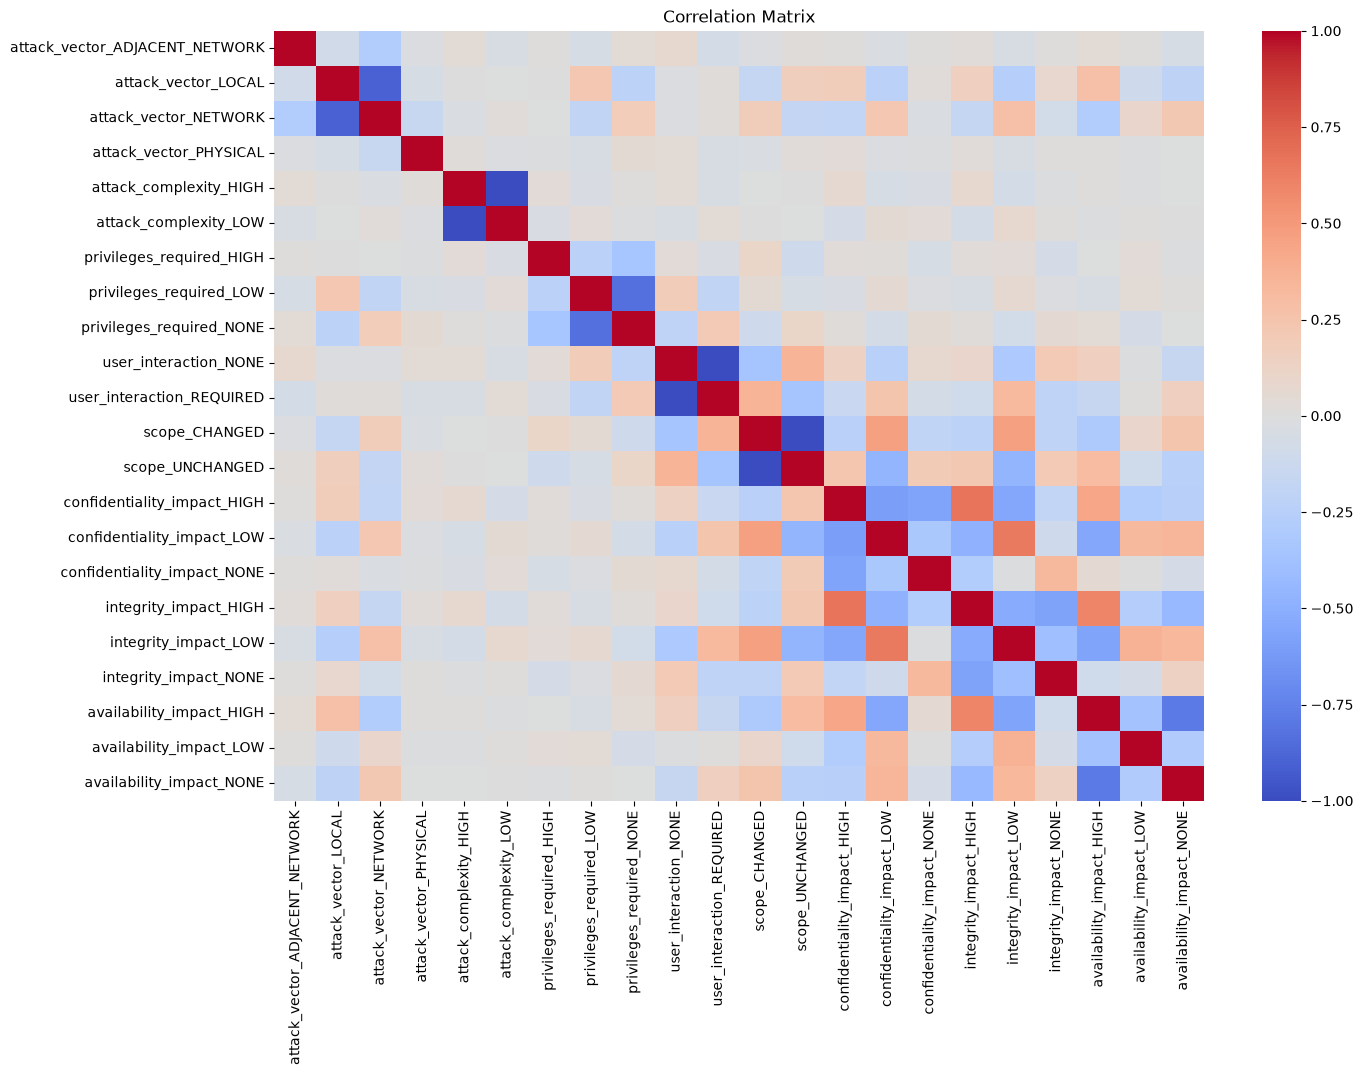

In [21]:
# Visualisasi korelasi antar variabel
plt.figure(figsize=(15, 10))
correlation_matrix = x_test.corr()

sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

Untuk setiap kelas target, kode membandingkan indikator kelas tersebut dengan fitur yang sudah diencoding.

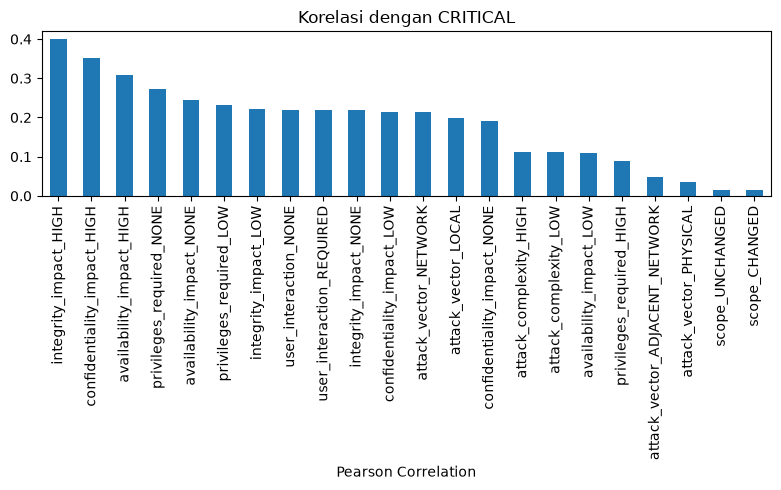

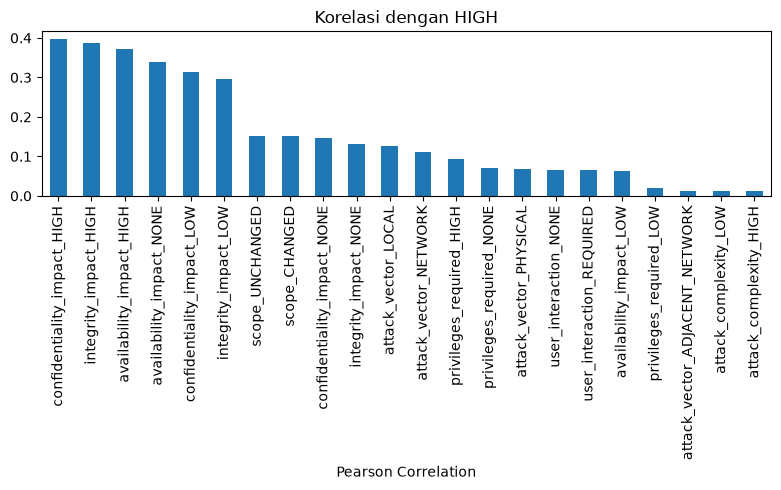

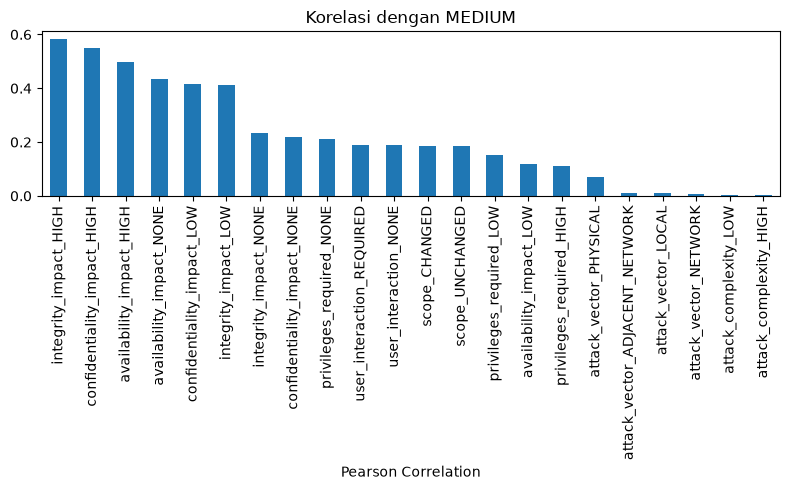

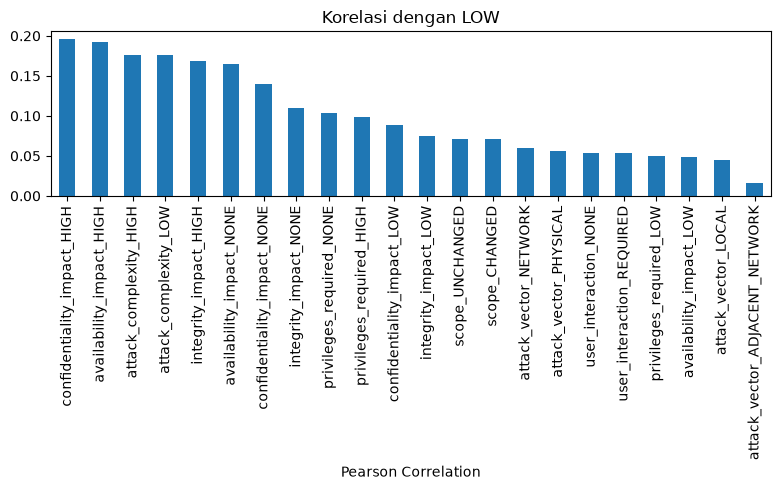

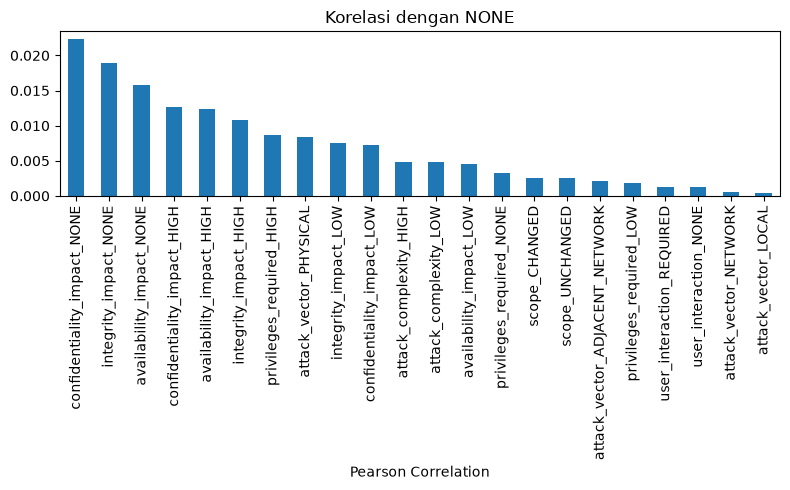

In [22]:
kelas_target = ["CRITICAL", "HIGH", "MEDIUM", "LOW", "NONE"]

for kelas in kelas_target:
    target = y.eq(kelas)

    correlation_matrix = x_test.corrwith(target).abs().sort_values(ascending=False)

    correlation_matrix.plot(kind="bar", figsize=(8, 5))
    plt.title(f"Korelasi dengan {kelas}")
    plt.xlabel("Pearson Correlation")
    plt.tight_layout()
    plt.show()

### 6. Melatih Model
Model yang digunakan oleh saya adalah Random Forest Classifier (RFC) dan juga di bandingkannya dengan Decision Tree (DCT)
Alasan saya menggunakan model tersebut karena dataset yang saya punya dan taget yang saya tentukan semuanya memiliki variabel yang bersifat kategorikal dan hal tersebut cocok jika digunakan oleh model tersebut.

Melatih Random Forest dan Decision Tree menggunakan data latih yang sama, sehingga hasil keduanya bisa dibandingkan pada data uji yang sama.

In [23]:
# Melatih Model
# Model Random Forest
rfc = RandomForestClassifier(
    n_estimators=100,
    random_state=1,
    n_jobs=-1
).fit(x_train, y_train)

# Model Decision Tree
dct = DecisionTreeClassifier(random_state=1).fit(x_train, y_train)

Menguji prediksi Random Forest pada data uji, kemudian menghitung accuracy, precision, recall, macro F1, dan laporan performa tiap kelas.

In [24]:
# Evaluasi pada model Random Forest
rfc_pred = rfc.predict(x_test)

accuracy_rfc = accuracy_score(y_test, rfc_pred)
precision_rfc = precision_score(y_test, rfc_pred, average="macro", zero_division=0)
f1_rfc = f1_score(y_test, rfc_pred, average="macro", zero_division=0)
recall_rfc = recall_score(y_test, rfc_pred, average="macro", zero_division=0)
classification_report_rfc = classification_report(y_test, rfc_pred, digits=4, zero_division=0)

print(f"Hasil RFC:\n{classification_report_rfc}")
# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    "accuracy": [accuracy_rfc],
    "precision":[precision_rfc],
    "recall": [recall_rfc],
    "f1": [f1_rfc]
}

df_results = pd.DataFrame(data, index=["RandomForestClassifier"])
df_results

Hasil RFC:
              precision    recall  f1-score   support

    CRITICAL     1.0000    0.9997    0.9999     11091
        HIGH     0.9997    0.9998    0.9997     36434
         LOW     0.9970    0.9988    0.9979      3288
      MEDIUM     0.9996    0.9997    0.9997     39927
        NONE     1.0000    0.4286    0.6000        14

    accuracy                         0.9996     90754
   macro avg     0.9993    0.8853    0.9194     90754
weighted avg     0.9996    0.9996    0.9996     90754



,accuracy,precision,recall,f1
RandomForestClassifier,0.999614,0.999262,0.885312,0.91943


Mengevaluasi Decision Tree dengan metrik yang sama agar hasilnya bisa dibandingkan langsung dengan Random Forest.

In [25]:
# Evaluasi pada model Decision Tree
dct_pred = dct.predict(x_test)
accuracy_dct = accuracy_score(y_test, dct_pred)
precision_dct = precision_score(y_test, dct_pred, average="macro", zero_division=0)
f1_dct = f1_score(y_test, dct_pred, average="macro", zero_division=0)
recall_dct = recall_score(y_test, dct_pred, average="macro", zero_division=0)
classification_report_dct = classification_report(y_test, dct_pred, digits=4, zero_division=0)

print(f"Hasil RFC:\n{classification_report_dct}")
# Membuat dictionary untuk menyimpan hasil evaluasi
df_results.loc["Decision Tree"] = [accuracy_dct, precision_dct, recall_dct, f1_dct]
df_results

Hasil RFC:
              precision    recall  f1-score   support

    CRITICAL     0.9997    0.9998    0.9998     11091
        HIGH     0.9996    0.9996    0.9996     36434
         LOW     0.9973    0.9985    0.9979      3288
      MEDIUM     0.9996    0.9997    0.9996     39927
        NONE     1.0000    0.4286    0.6000        14

    accuracy                         0.9995     90754
   macro avg     0.9992    0.8852    0.9194     90754
weighted avg     0.9995    0.9995    0.9995     90754



,accuracy,precision,recall,f1
RandomForestClassifier,0.999614,0.999262,0.885312,0.91943
Decision Tree,0.999537,0.999243,0.885232,0.91938


Membandingkan accuracy dan macro F1 Decision Tree pada data latih dan data uji untuk melihat indikasi overfitting.

In [26]:

y_train_dt = dct.predict(x_train)
y_test_dt = dct.predict(x_test)

print("Decision Tree")
print("Training Accuracy:",
      accuracy_score(y_train, y_train_dt))
print("Testing Accuracy:",
      accuracy_score(y_test, y_test_dt))

print("Training Macro F1:",
      f1_score(y_train, y_train_dt,
               average="macro", zero_division=0))
print("Testing Macro F1:",
      f1_score(y_test, y_test_dt,
               average="macro", zero_division=0))


Decision Tree
Training Accuracy: 1.0
Testing Accuracy: 0.9995372104810807
Training Macro F1: 1.0
Testing Macro F1: 0.9193801475372227


Menghitung metrik training dan testing untuk Random Forest.

In [27]:

y_train_dt = rfc.predict(x_train)
y_test_dt = rfc.predict(x_test)

print("Random Forest:")
print("Training Accuracy:",
      accuracy_score(y_train, y_train_dt))
print("Testing Accuracy:",
      accuracy_score(y_test, y_test_dt))

print("Training Macro F1:",
      f1_score(y_train, y_train_dt,
               average="macro", zero_division=0))
print("Testing Macro F1:",
      f1_score(y_test, y_test_dt,
               average="macro", zero_division=0))


Random Forest:
Training Accuracy: 1.0
Testing Accuracy: 0.9996143420675673
Training Macro F1: 1.0
Testing Macro F1: 0.9194300405767544


### Interpretasi Sementara Hasil

Pada output saat ini, accuracy kedua model sekitar **99,97%**, tetapi macro F1 sekitar **91,94%**. Kelas `NONE` hanya memiliki **14 sampel uji** dan recall **0,42**; karena itu accuracy saja tidak cukup untuk menyatakan model unggul pada semua kelas.

Menyimpan model Random Forest dan Decision Tree dalam file `.joblib` agar dapat digunakan kembali tanpa melatih model dari awal.

In [28]:
joblib.dump(rfc, "rfc_model.joblib")
joblib.dump(dct, "dct_model.joblib")

['dct_model.joblib']

## Kesimpulan

Pada praktik ini saya menggunakan **302.512 data CVE** dengan `base_severity` sebagai target klasifikasi dan delapan fitur kategorikal CVSS sebagai prediktor. Dataset dibagi menjadi **70% data latih (211.758 baris)** dan **30% data uji (90.754 baris)** menggunakan `train_test_split()` dengan `stratify=y` agar proporsi kelas tetap terjaga.

Model Random Forest memperoleh accuracy **99,96%** dan macro F1-score **91,94%**, sedangkan Decision Tree memperoleh accuracy **99,95%** dan macro F1-score **91,94%**. Keduanya menunjukkan performa tinggi pada data uji, tetapi belum tentu memiliki kemampuan yang sama pada setiap kelas. Hal ini terlihat dari recall kelas `NONE` yang hanya **42,86%**, dengan jumlah **14 sampel** uji.

Dataset tidak memiliki baris duplikat ketika `cve_id` disertakan. Namun, banyak kombinasi fitur yang sama setelah `cve_id` dikeluarkan tidak berarti kerentanannya merupakan duplikat, sehingga baris tersebut tidak otomatis dihapus.

Dengan demikian, Random Forest memiliki hasil sedikit lebih baik daripada Decision Tree pada pengujian ini. Namun, evaluasi lanjutan dan analisis kesalahan masih diperlukan sebelum menarik kesimpulan akhir mengenai keandalan model..